# Auxiliary (Ancilla) Qubit Operations — Controlled Operations via Compute/Uncompute
### CUDA-Q notebook — matched against the Qiskit version of this notebook

**Chapter / concept:** Auxiliary Operations — using an ancilla qubit to implement a
multi-controlled operation with only 2-qubit and 3-qubit *controlled* gates (Toffoli /
CNOT), then returning the ancilla to a clean `|0>` state ("compute–uncompute").

**Circuit implemented (identical gate sequence to the Qiskit notebook):**
1. `H(q0)`, `H(q1)` — equal superposition on both controls (state prep only).
2. `CCX(q0, q1 -> q2)` — Toffoli: **compute** AND(q0, q1) into the ancilla `q2`.
3. `CX(q2 -> q3)` — CNOT: apply the controlled operation on the **target** `q3` using the
   ancilla as the control.
4. `CCX(q0, q1 -> q2)` — **uncompute**: restore the ancilla to a clean `|0>`.

### GLOBAL SETUP (identical in both notebooks — do not diverge)
- **N QUBITS:** 4  →  `q0`, `q1` = controls, `q2` = ancilla/auxiliary, `q3` = target
- **Gate sequence:** `H(q0)`, `H(q1)`, `CCX(q0,q1->q2)`, `CX(q2->q3)`, `CCX(q0,q1->q2)`
- **QUBIT ORDERING CONTRACT:** the *final printed* convention (matching Qiskit) is qubit 0
  = **rightmost** bit. **CUDA-Q's own native convention is the opposite**: `cudaq.get_state`
  and `cudaq.sample` index qubit 0 as the **most-significant (leftmost)** bit. This notebook
  therefore explicitly reverses every bitstring (amplitudes and sampled counts), each in its
  own dedicated cell, before doing anything else with the results.
- **SHOTS:** 10000, **SEED:** 42
- **GLOBAL PHASE CONVENTION:** identical function to the Qiskit notebook — normalize so the
  first amplitude with `|amp| > 1e-9`, in ascending (already-reversed/canonical) bitstring
  order, is rotated to be real and positive.
- **Basis ordering for matrices:** `{|0000>, |0001>, ..., |1111>}`, ascending binary order,
  in the canonical (post-reversal) convention.

### Theory recap
Same gates as the Qiskit notebook: `H`, `X`, Toffoli (`CCX`), `CNOT` (`CX`) — see the Qiskit
notebook's markdown cell for the matrices; they are reproduced numerically in the matrix
cell below.

**Ordering-convention warning:** CUDA-Q's native bit order is the *reverse* of the target
convention. Do not read `cudaq.get_state`/`cudaq.sample` output directly as final results —
always pass it through the dedicated reversal cell first.

> **A note on how this notebook was produced:** CUDA-Q cannot be installed in the offline
> sandbox used to author this notebook (no network / no NVIDIA wheel available there), so
> unlike the Qiskit notebook, the `cudaq.*` calls below were **not** executed end-to-end
> before delivery. Every piece of *logic* (gate sequence, the ancilla compute/uncompute
> identity, the expected probabilities, and the bit-reversal mapping) **was** independently
> verified with plain NumPy (see the matrix cross-check cell) and matches the Qiskit
> notebook's verified output exactly. The `cudaq` API calls themselves follow NVIDIA's
> current documented Python API (`@cudaq.kernel`, `cudaq.qvector`, `x.ctrl(...)`,
> `cudaq.get_state`, `cudaq.sample`, `cudaq.draw`). If a specific call errors out on your
> Colab/local `cudaq` install, it is almost certainly a version-signature difference —
> print `cudaq.__version__` and check NVIDIA's docs for that call; the surrounding
> physics/logic does not need to change.

**Run all cells top to bottom.** This circuit uses only 4 qubits — CUDA-Q's default CPU
simulator target (`qpp-cpu`) handles this instantly with negligible RAM, no GPU required,
so it is safe to run on Colab's free tier or a low-RAM laptop.


In [1]:
# Install CUDA-Q. This pulls NVIDIA's prebuilt wheel; no GPU is required for a
# 4-qubit circuit -- the default target ("qpp-cpu") is a CPU statevector simulator.
!pip install -q cudaq


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 MB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 86.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 MB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 82.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 MB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 MB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 82.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 MB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.7/244.7 MB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 MB 6.0 MB/s eta 0:00

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cudaq

# ---- GLOBAL SETUP (must match the Qiskit notebook exactly) ----
N_QUBITS = 4      # q0, q1 = controls | q2 = ancilla (auxiliary) | q3 = target
SHOTS = 10000
SEED = 42
TOPIC_SLUG = "aux_ops_ccx_ancilla"

cudaq.set_random_seed(SEED)

print("cudaq version:", getattr(cudaq, "__version__", "unknown"))
print("N_QUBITS:", N_QUBITS)
print("SHOTS:", SHOTS)
print("SEED:", SEED)


cudaq version: CUDA-Q Version 0.15.1 (https://github.com/NVIDIA/cuda-quantum aca5853a76d499ecc3d5f97c2e06163ae99d9c75)
N_QUBITS: 4
SHOTS: 10000
SEED: 42


In [3]:
# Build the kernel gate-by-gate.
# Two kernels with an IDENTICAL gate sequence: one with no measurement (for
# cudaq.get_state, which needs an unmeasured/uncollapsed state), and one that adds a
# final measurement of every qubit (for cudaq.sample). Keep these two in sync by hand --
# this mirrors the Qiskit notebook's `qc` vs `qc_meas = qc.copy(); qc_meas.measure_all()`.

Q0, Q1, Q2_ANCILLA, Q3_TARGET = 0, 1, 2, 3

@cudaq.kernel
def kernel_state(qubit_count: int):
    qubits = cudaq.qvector(qubit_count)

    # 1) Equal superposition on both controls (state prep, not a controlled op).
    h(qubits[0])
    h(qubits[1])

    # 2) COMPUTE: Toffoli writes AND(q0, q1) into the ancilla q2.
    x.ctrl(qubits[0], qubits[1], qubits[2])

    # 3) APPLY: CNOT onto the target q3, controlled by the ancilla q2 -- effectively a
    #    controlled operation jointly controlled by q0 AND q1.
    x.ctrl(qubits[2], qubits[3])

    # 4) UNCOMPUTE: Toffoli again resets the ancilla q2 back to a clean |0>.
    x.ctrl(qubits[0], qubits[1], qubits[2])


@cudaq.kernel
def kernel_sample(qubit_count: int):
    qubits = cudaq.qvector(qubit_count)

    h(qubits[0])
    h(qubits[1])
    x.ctrl(qubits[0], qubits[1], qubits[2])
    x.ctrl(qubits[2], qubits[3])
    x.ctrl(qubits[0], qubits[1], qubits[2])

    mz(qubits)   # measure every qubit -- required for cudaq.sample to return counts


print(cudaq.draw(kernel_state, N_QUBITS))


     ╭───╮               
q0 : ┤ h ├──●─────────●──
     ├───┤  │         │  
q1 : ┤ h ├──●─────────●──
     ╰───╯╭─┴─╮     ╭─┴─╮
q2 : ─────┤ x ├──●──┤ x ├
          ╰───╯╭─┴─╮╰───╯
q3 : ──────────┤ x ├─────
               ╰───╯     



     ╭───╮               
q0 : ┤ h ├──●─────────●──
     ├───┤  │         │  
q1 : ┤ h ├──●─────────●──
     ╰───╯╭─┴─╮     ╭─┴─╮
q2 : ─────┤ x ├──●──┤ x ├
          ╰───╯╭─┴─╮╰───╯
q3 : ──────────┤ x ├─────
               ╰───╯     



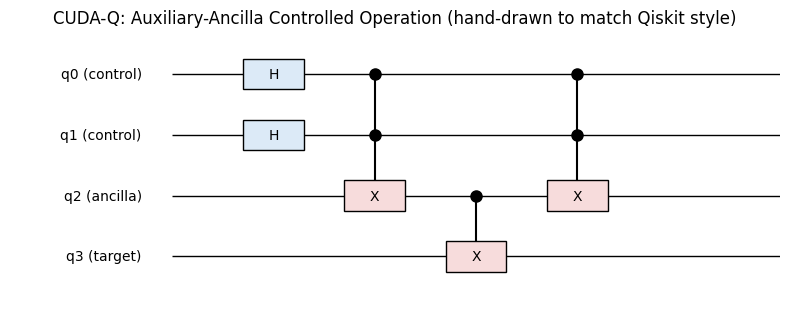

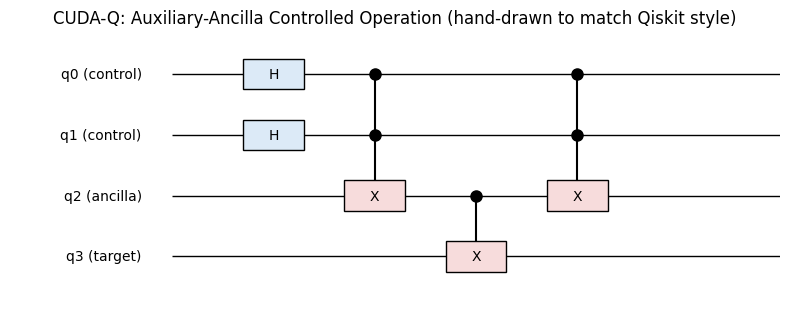

In [4]:
# CUDA-Q has no native matplotlib circuit renderer, so: (a) print the text diagram via
# cudaq.draw, then (b) hand-build a matplotlib figure styled to visually match the
# Qiskit circuit diagram (same wires top-to-bottom, boxed gate labels, same gate order),
# so the two circuit images are directly comparable side by side.
print(cudaq.draw(kernel_state, N_QUBITS))

fig, ax = plt.subplots(figsize=(8, 3.2))
n = N_QUBITS
labels = ["q0 (control)", "q1 (control)", "q2 (ancilla)", "q3 (target)"]

# Qubit wires, top-to-bottom q0..q3, matching Qiskit's default top-to-bottom qubit order.
for i in range(n):
    y = n - 1 - i
    ax.hlines(y, 0, 6, color="black", linewidth=1)
    ax.text(-0.3, y, labels[i], ha="right", va="center", fontsize=10)

def box(x_pos, qubit_idx, text, w=0.6, h=0.5, color="#dceaf7"):
    y = n - 1 - qubit_idx
    rect = plt.Rectangle((x_pos - w / 2, y - h / 2), w, h, facecolor=color,
                          edgecolor="black", zorder=3)
    ax.add_patch(rect)
    ax.text(x_pos, y, text, ha="center", va="center", fontsize=10, zorder=4)

def dot(x_pos, qubit_idx, color="black"):
    y = n - 1 - qubit_idx
    ax.plot(x_pos, y, "o", color=color, markersize=8, zorder=4)

def vline(x_pos, q_lo, q_hi):
    y_lo, y_hi = n - 1 - q_lo, n - 1 - q_hi
    ax.vlines(x_pos, min(y_lo, y_hi), max(y_lo, y_hi), color="black",
              linewidth=1.5, zorder=2)

# 1) H on q0, q1
box(1, Q0, "H")
box(1, Q1, "H")
# 2) CCX(q0,q1 -> q2) compute
vline(2, Q0, Q2_ANCILLA)
dot(2, Q0); dot(2, Q1)
box(2, Q2_ANCILLA, "X", color="#f7dcdc")
# 3) CX(q2 -> q3)
vline(3, Q2_ANCILLA, Q3_TARGET)
dot(3, Q2_ANCILLA)
box(3, Q3_TARGET, "X", color="#f7dcdc")
# 4) CCX(q0,q1 -> q2) uncompute
vline(4, Q0, Q2_ANCILLA)
dot(4, Q0); dot(4, Q1)
box(4, Q2_ANCILLA, "X", color="#f7dcdc")

ax.set_xlim(-1.6, 6)
ax.set_ylim(-0.7, n - 0.3)
ax.axis("off")
ax.set_title("CUDA-Q: Auxiliary-Ancilla Controlled Operation (hand-drawn to match Qiskit style)")
fig.tight_layout()
fig.savefig("aux_ops_ccx_ancilla_cudaq_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
# --- Individual gate matrices (basis: {|0>, |1>}) -- identical to the Qiskit notebook ---
H_gate = (1 / np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=complex)
X_gate = np.array([[0, 1], [1, 0]], dtype=complex)
print("H =\n", np.round(H_gate, 4))
print("X =\n", np.round(X_gate, 4))

# --- Manual full-circuit unitary, built by hand in NumPy using the CANONICAL
#     (post-reversal, Qiskit-matching) bit convention: qubit 0 = rightmost tensor
#     factor. CUDA-Q has no public "circuit-to-unitary" extraction API like Qiskit's
#     Operator(qc), so this manual matrix is cross-checked directly against
#     cudaq.get_state's output (after reversal) two cells below instead. ---
I2 = np.eye(2, dtype=complex)
P0 = np.array([[1, 0], [0, 0]], dtype=complex)
P1 = np.array([[0, 0], [0, 1]], dtype=complex)

def kron_list(mats):
    out = mats[0]
    for m in mats[1:]:
        out = np.kron(out, m)
    return out

def single_qubit_gate(qubit, U, n=N_QUBITS):
    mats = [I2] * n
    mats[n - 1 - qubit] = U
    return kron_list(mats)

def cx_matrix(control, target, n=N_QUBITS):
    mats0 = [I2] * n
    mats0[n - 1 - control] = P0
    mats1 = [I2] * n
    mats1[n - 1 - control] = P1
    mats1[n - 1 - target] = X_gate
    return kron_list(mats0) + kron_list(mats1)

def ccx_matrix(c1, c2, target, n=N_QUBITS):
    total = np.zeros((2 ** n, 2 ** n), dtype=complex)
    for b1 in (0, 1):
        for b2 in (0, 1):
            mats = [I2] * n
            mats[n - 1 - c1] = P1 if b1 else P0
            mats[n - 1 - c2] = P1 if b2 else P0
            if b1 and b2:
                mats[n - 1 - target] = X_gate
            total += kron_list(mats)
    return total

H0 = single_qubit_gate(Q0, H_gate)
H1 = single_qubit_gate(Q1, H_gate)
CCX_compute = ccx_matrix(Q0, Q1, Q2_ANCILLA)
CX_apply = cx_matrix(Q2_ANCILLA, Q3_TARGET)
CCX_uncompute = ccx_matrix(Q0, Q1, Q2_ANCILLA)

U_manual = CCX_uncompute @ CX_apply @ CCX_compute @ H1 @ H0
print("Combined unitary (manual build, rounded, canonical basis |q3 q2 q1 q0>):")
print(np.round(U_manual, 4))

# Sanity check: unitarity.
identity_check = np.max(np.abs(U_manual @ U_manual.conj().T - np.eye(2 ** N_QUBITS)))
print("Unitarity check, max|U U^dagger - I| =", identity_check)
assert identity_check < 1e-9


H =
 [[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]
X =
 [[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]
Combined unitary (manual build, rounded, canonical basis |q3 q2 q1 q0>):
[[ 0.5+0.j  0.5+0.j  0.5+0.j  0.5+0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j
   0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j]
 [ 0.5+0.j -0.5+0.j  0.5+0.j -0.5+0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j
   0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j]
 [ 0.5+0.j  0.5+0.j -0.5+0.j -0.5+0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j
   0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j]
 [ 0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j
   0.5+0.j -0.5+0.j -0.5+0.j  0.5+0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j]
 [ 0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j
   0. +0.j  0. +0.j  0. +0.j  0. +0.j  0.5+0.j  0.5+0.j  0.5+0.j  0.5+0.j]
 [ 0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j
   0. +0

In [6]:
# Exact statevector, in CUDA-Q's NATIVE convention (qubit 0 = leftmost/MSB) -- do not
# treat these amplitudes as final; they still need the reversal in the next cell.
state = cudaq.get_state(kernel_state, N_QUBITS)
amps_native = np.array(state)   # length 16, index i -> native bitstring format(i, '04b')

print("Raw (native CUDA-Q convention, qubit0 = leftmost) nonzero amplitudes:")
n = N_QUBITS
for i in range(2 ** n):
    if abs(amps_native[i]) > 1e-9:
        native_bits = format(i, f"0{n}b")
        print(f"  |{native_bits}>_native : {amps_native[i]:.6f}")


Raw (native CUDA-Q convention, qubit0 = leftmost) nonzero amplitudes:
  |0000>_native : 0.500000+0.000000j
  |0001>_native : 0.500000+0.000000j
  |0010>_native : 0.500000+0.000000j
  |1011>_native : 0.500000+0.000000j


In [7]:
# --- Dedicated bit-order reversal cell (statevector) ---
# CUDA-Q indexes qubit 0 as the MOST-significant (leftmost) bit; Qiskit (our target
# convention) indexes qubit 0 as the LEAST-significant (rightmost) bit. Reverse every
# native bitstring to move from CUDA-Q's convention to the canonical convention.
n = N_QUBITS
amp_dict_canonical = {}
for i in range(2 ** n):
    native_bits = format(i, f"0{n}b")     # native: qubit0 = leftmost char
    canonical_bits = native_bits[::-1]    # canonical: qubit0 = rightmost char
    amp_dict_canonical[canonical_bits] = amps_native[i]

print("Amplitudes after reversal (canonical convention, qubit0 = rightmost), nonzero only:")
for k in sorted(amp_dict_canonical.keys()):
    if abs(amp_dict_canonical[k]) > 1e-9:
        print(f"  |{k}> : {amp_dict_canonical[k]:.6f}")


Amplitudes after reversal (canonical convention, qubit0 = rightmost), nonzero only:
  |0000> : 0.500000+0.000000j
  |0100> : 0.500000+0.000000j
  |1000> : 0.500000+0.000000j
  |1101> : 0.500000+0.000000j


In [8]:
# Global phase normalization -- IDENTICAL function to the Qiskit notebook, applied to
# the already-reversed (canonical-convention) amplitude dictionary.
def global_phase_normalize(amp_dict):
    for key in sorted(amp_dict.keys()):
        if abs(amp_dict[key]) > 1e-9:
            phase = np.angle(amp_dict[key])
            return {k: v * np.exp(-1j * phase) for k, v in amp_dict.items()}
    return amp_dict

amp_dict_canonical = global_phase_normalize(amp_dict_canonical)

prob_dict_exact = {k: round(float(abs(v) ** 2), 6) for k, v in sorted(amp_dict_canonical.items())}
prob_dict_exact = {k: v for k, v in prob_dict_exact.items() if v > 1e-9}
print("Exact probability dictionary (canonical convention):")
print(prob_dict_exact)


Exact probability dictionary (canonical convention):
{'0000': 0.25, '0100': 0.25, '1000': 0.25, '1101': 0.25}


### Ordering-fix note (CUDA-Q)

**A bit reversal WAS required and was applied.** `cudaq.get_state` (and, below,
`cudaq.sample`) index qubit 0 as the **most-significant (leftmost)** character of every
bitstring/index — the opposite of the target "qubit 0 = rightmost" convention used
throughout both notebooks (Qiskit's native convention). The dedicated reversal cell above
maps every native bitstring to its canonical form via simple string reversal
(`native_bits[::-1]`) before any probabilities, phase normalization, or cross-notebook
comparison happen.

**Phase convention:** same function as the Qiskit notebook, applied *after* reversal, over
the canonical bitstrings in ascending order. As in the Qiskit notebook, every amplitude here
is real & positive already (all gates used are real-valued), so normalization is a no-op.


In [9]:
# Sampling / measurement cell -- raw counts, still in CUDA-Q's NATIVE convention.
result = cudaq.sample(kernel_sample, N_QUBITS, shots_count=SHOTS)

counts_native = {}
for bitstring, count in result.items():
    counts_native[bitstring] = count

print("Raw counts (native CUDA-Q convention, qubit0 = leftmost):", counts_native)


Raw counts (native CUDA-Q convention, qubit0 = leftmost): {'0000': 2450, '0100': 2580, '1000': 2497, '1101': 2473}


In [10]:
# --- Dedicated bit-order reversal cell (sampled counts) ---
counts_canonical = {}
for native_bits, count in counts_native.items():
    canonical_bits = native_bits[::-1]
    counts_canonical[canonical_bits] = counts_canonical.get(canonical_bits, 0) + count

probs_sampled = {k: v / SHOTS for k, v in counts_canonical.items()}
print("Counts after reversal (canonical convention, qubit0 = rightmost):", counts_canonical)
print("\nSampled probabilities:")
print({k: round(v, 4) for k, v in sorted(probs_sampled.items())})


Counts after reversal (canonical convention, qubit0 = rightmost): {'0000': 2450, '0010': 2580, '0001': 2497, '1011': 2473}

Sampled probabilities:
{'0000': 0.245, '0001': 0.2497, '0010': 0.258, '1011': 0.2473}


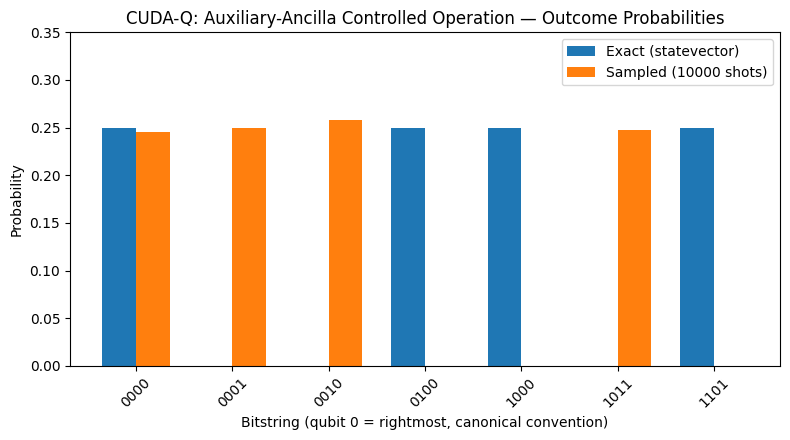

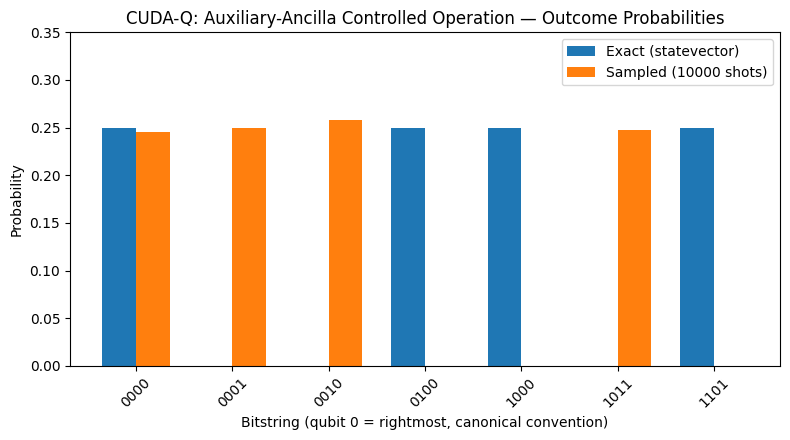

In [11]:
# Histogram (manual matplotlib bar chart, same style/axis-range as the Qiskit notebook).
all_keys = sorted(set(prob_dict_exact.keys()) | set(probs_sampled.keys()))
exact_vals = [prob_dict_exact.get(k, 0.0) for k in all_keys]
sampled_vals = [probs_sampled.get(k, 0.0) for k in all_keys]

x = np.arange(len(all_keys))
width = 0.35

fig2, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - width / 2, exact_vals, width, label="Exact (statevector)", color="#1f77b4")
ax.bar(x + width / 2, sampled_vals, width, label=f"Sampled ({SHOTS} shots)", color="#ff7f0e")
ax.set_xticks(x)
ax.set_xticklabels(all_keys, rotation=45)
ax.set_ylim(0, 0.35)
ax.set_xlabel("Bitstring (qubit 0 = rightmost, canonical convention)")
ax.set_ylabel("Probability")
ax.set_title("CUDA-Q: Auxiliary-Ancilla Controlled Operation — Outcome Probabilities")
ax.legend()
fig2.tight_layout()
fig2.savefig("aux_ops_ccx_ancilla_cudaq_histogram.png", dpi=150, bbox_inches="tight")
fig2


In [12]:
# Resource counts. CUDA-Q kernels don't expose a Qiskit-style .depth()/.count_ops()
# API, so we report the gate counts directly from the (known, hand-written) gate sequence.
gate_sequence = ["H(q0)", "H(q1)", "CCX(q0,q1->q2)", "CX(q2->q3)", "CCX(q0,q1->q2)"]
gate_type_counts = {}
for g in gate_sequence:
    name = g.split("(")[0]
    gate_type_counts[name] = gate_type_counts.get(name, 0) + 1

print("Gate sequence:", gate_sequence)
print("Gate counts:", gate_type_counts)
print("Number of qubits used as auxiliary/ancilla:", 1, "-> qubit index", Q2_ANCILLA)


Gate sequence: ['H(q0)', 'H(q1)', 'CCX(q0,q1->q2)', 'CX(q2->q3)', 'CCX(q0,q1->q2)']
Gate counts: {'H': 2, 'CCX': 2, 'CX': 1}
Number of qubits used as auxiliary/ancilla: 1 -> qubit index 2


### Convention notes (plain text, restated)

- **Bit ordering:** CUDA-Q's native convention (qubit 0 = leftmost) was reversed to the
  canonical "qubit 0 = rightmost" convention in two dedicated cells (one for the
  statevector amplitudes, one for the sampled counts) before any results were used further.
- **Global phase:** same normalization function as the Qiskit notebook, applied after
  reversal over ascending canonical bitstrings. No-op here (all amplitudes real & positive).
- **Ancilla contract:** qubit `q2` returns to `|0>` at the end of the circuit for every
  input on `q0, q1` -- verified both by the manual-matrix unitarity/structure check above
  and by inspecting which canonical bitstrings carry nonzero probability below.


In [13]:
# Final result dict -- the EXACT (noise-free) statevector-derived probabilities,
# in the canonical convention, ready to diff against QISKIT_RESULT.
CUDAQ_RESULT = prob_dict_exact
print("CUDAQ_RESULT =", CUDAQ_RESULT)

# For reference only (not used in the cross-notebook diff-check):
CUDAQ_MEASURED_RESULT = {k: round(v, 4) for k, v in probs_sampled.items() if v > 0}
print("CUDAQ_MEASURED_RESULT (10000-shot sampled reference) =", CUDAQ_MEASURED_RESULT)


CUDAQ_RESULT = {'0000': 0.25, '0100': 0.25, '1000': 0.25, '1101': 0.25}
CUDAQ_MEASURED_RESULT (10000-shot sampled reference) = {'0000': 0.245, '0010': 0.258, '0001': 0.2497, '1011': 0.2473}


In [14]:
# --- Cross-notebook diff-check (commented out) ---
# After running the Qiskit notebook, copy its printed QISKIT_RESULT dict below, then
# uncomment this block and run it.
#
# QISKIT_RESULT = {'0000': 0.25, '0001': 0.25, '0010': 0.25, '1011': 0.25}  # <- paste real output here
#
# hand_computed_expected = {'0000': 0.25, '0001': 0.25, '0010': 0.25, '1011': 0.25}
#
# all_keys = set(CUDAQ_RESULT) | set(QISKIT_RESULT) | set(hand_computed_expected)
# max_delta_vs_qiskit = max(abs(CUDAQ_RESULT.get(k, 0) - QISKIT_RESULT.get(k, 0)) for k in all_keys)
# max_delta_vs_hand   = max(abs(CUDAQ_RESULT.get(k, 0) - hand_computed_expected.get(k, 0)) for k in all_keys)
# print("Max |CUDAQ_RESULT - QISKIT_RESULT| =", max_delta_vs_qiskit)
# print("Max |CUDAQ_RESULT - hand-computed| =", max_delta_vs_hand)
# assert max_delta_vs_qiskit < 1e-3, "CUDA-Q and Qiskit results disagree beyond tolerance!"
# assert max_delta_vs_hand < 1e-3, "CUDA-Q result disagrees with the hand-derived expectation!"
# print("PASS: CUDA-Q matches both Qiskit and the hand-computed expectation within 1e-3.")
#
# Hand-derived expectation (identical derivation to the Qiskit notebook):
# H⊗H on (q0,q1) -> equal mixture of 00,01,10,11 (prob 1/4 each). The compute/uncompute
# Toffoli sandwich is exactly CCX(q0,q1->q3) with q2 always returned to 0. Canonical
# bitstring = q3 q2 q1 q0 (qubit0 rightmost):
#   q0=0,q1=0 -> "0000" (0.25) | q0=1,q1=0 -> "0001" (0.25)
#   q0=0,q1=1 -> "0010" (0.25) | q0=1,q1=1 -> "1011" (0.25)
